In [1]:
import numpy as np
import pandas as pd

# Read Data set


In [2]:
df = pd.read_excel('marketing_campaign.xlsx')


In [3]:
print(df.shape)
df.head()

(2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


# Exploring the data


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,2240.0,NaN,NaN,NaN,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,NaN,NaN,NaN,1968.805804,11.984069,1893.0,1959.0,1970.0,1977.0,1996.0
Education,2240,5,Graduation,1127,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_Status,2240,8,Married,864,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Income,2216.0,NaN,NaN,NaN,52247.251354,25173.076661,1730.0,35303.0,51381.5,68522.0,666666.0
Kidhome,2240.0,NaN,NaN,NaN,0.444196,0.538398,0.0,0.0,0.0,1.0,2.0
Teenhome,2240.0,NaN,NaN,NaN,0.50625,0.544538,0.0,0.0,0.0,1.0,2.0
Dt_Customer,2240,663,2012-08-31,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Recency,2240.0,NaN,NaN,NaN,49.109375,28.962453,0.0,24.0,49.0,74.0,99.0
MntWines,2240.0,NaN,NaN,NaN,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0


In [7]:
df.isnull().sum()

,0
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['Income'] = df['Income'].fillna(df['Income'].median())

In [10]:
df['Income'].isnull().sum()

np.int64(0)

In [11]:
df[['Income', 'Year_Birth']].describe()

,Income,Year_Birth
count,2240.000000,2240.000000
mean,52237.975446,1968.805804
std,25037.955891,11.984069
min,1730.000000,1893.000000
25%,35538.750000,1959.000000
50%,51381.500000,1970.000000
75%,68289.750000,1977.000000
max,666666.000000,1996.000000


In [12]:

print(df[df['Income'] > 200000])
print(df[df['Year_Birth'] < 1930])

        ID  Year_Birth   Education Marital_Status    Income  Kidhome  \
2233  9432        1977  Graduation       Together  666666.0        1   

      Teenhome Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  \
2233         0  2013-06-02       23         9  ...                  6   

      AcceptedCmp3  AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  \
2233             0             0             0             0             0   

      Complain  Z_CostContact  Z_Revenue  Response  
2233         0              3         11         0  

[1 rows x 29 columns]
        ID  Year_Birth Education Marital_Status   Income  Kidhome  Teenhome  \
192   7829        1900  2n Cycle       Divorced  36640.0        1         0   
239  11004        1893  2n Cycle         Single  60182.0        0         1   
339   1150        1899       PhD       Together  83532.0        0         0   

    Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  AcceptedCmp3  \
192  2013-09-26       99     

In [13]:
# Remove the extreme outliers
df = df[df['Income'] < 200000]
df = df[df['Year_Birth'] > 1930]

print(df.shape)

(2236, 29)


In [14]:
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'])
df['Education'].value_counts()

,count
Education,
Graduation,1126
PhD,485
Master,370
2n Cycle,201
Basic,54


In [15]:
df['Marital_Status'].value_counts()

,count
Marital_Status,
Married,864
Together,578
Single,479
Divorced,231
Widow,77
Alone,3
Absurd,2
YOLO,2


In [16]:

df['Marital_Status'] = df['Marital_Status'].replace({
    'Alone': 'Single',
    'Absurd': 'Single',
    'YOLO': 'Single'
})


In [17]:

df['Marital_Status'].value_counts()

,count
Marital_Status,
Married,864
Together,578
Single,486
Divorced,231
Widow,77


In [18]:
# Age instead of raw birth year (more interpretable, and "today" is fixed for consistency)
df['Age'] = 2015 - df['Year_Birth']  # dataset is from ~2014-2015, so using that as reference


In [19]:
# Total number of children at home
df['Total_Kids'] = df['Kidhome'] + df['Teenhome']

In [20]:
# Total amount spent across all product categories
spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['Total_Spend'] = df[spend_cols].sum(axis=1)

In [21]:
# Total number of purchases across all channels
purchase_cols = ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
df['Total_Purchases'] = df[purchase_cols].sum(axis=1)

In [22]:
# Customer tenure in days (how long they've been a customer, relative to the most recent enrollment date)
df['Tenure_Days'] = (df['Dt_Customer'].max() - df['Dt_Customer']).dt.days

In [23]:
# Total number of campaigns accepted previously (useful predictor for Response)
campaign_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']
df['Total_Campaigns_Accepted'] = df[campaign_cols].sum(axis=1)

In [24]:
df[['Age', 'Total_Kids', 'Total_Spend', 'Total_Purchases', 'Tenure_Days', 'Total_Campaigns_Accepted']].describe()

,Age,Total_Kids,Total_Spend,Total_Purchases,Tenure_Days,Total_Campaigns_Accepted
count,2236.000000,2236.000000,2236.000000,2236.000000,2236.000000,2236.000000
mean,46.101968,0.950805,605.986583,14.872540,353.773256,0.297853
std,11.703281,0.752204,601.865156,7.677874,202.181561,0.678737
min,19.000000,0.000000,5.000000,0.000000,0.000000,0.000000
25%,38.000000,0.000000,69.000000,8.000000,180.750000,0.000000
50%,45.000000,1.000000,396.500000,15.000000,356.000000,0.000000
75%,56.000000,1.000000,1045.500000,21.000000,529.000000,0.000000
max,75.000000,3.000000,2525.000000,44.000000,699.000000,4.000000


In [25]:
# Z_CostContact and Z_Revenue are constant (no predictive value), ID isn't useful for modeling
df = df.drop(columns=['Z_CostContact', 'Z_Revenue', 'ID'])
df.shape

(2236, 32)

In [26]:
df_encoded = pd.get_dummies(df, columns=['Education', 'Marital_Status'], drop_first=True)
df_encoded.shape

(2236, 38)

In [27]:
df.to_csv('marketing_campaign_cleaned.csv', index=False)

from google.colab import files
files.download('marketing_campaign_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# EDA

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
print(df['Response'].value_counts(normalize=True))

Response
0    0.850626
1    0.149374
Name: proportion, dtype: float64


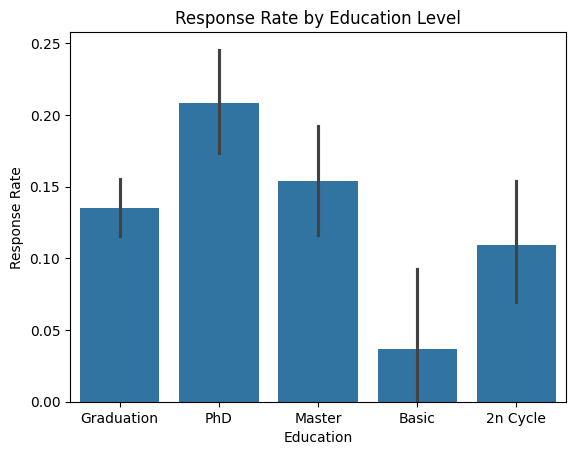

In [30]:
sns.barplot(data=df, x='Education', y='Response')
plt.title('Response Rate by Education Level')
plt.ylabel('Response Rate')
plt.show()

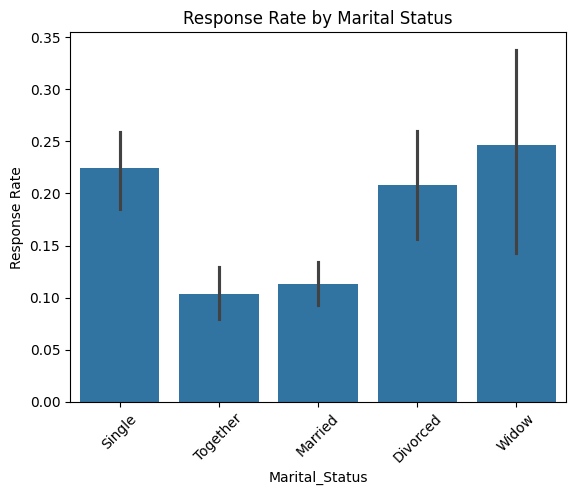

In [31]:
sns.barplot(data=df, x='Marital_Status', y='Response')
plt.title('Response Rate by Marital Status')
plt.ylabel('Response Rate')
plt.xticks(rotation=45)
plt.show()

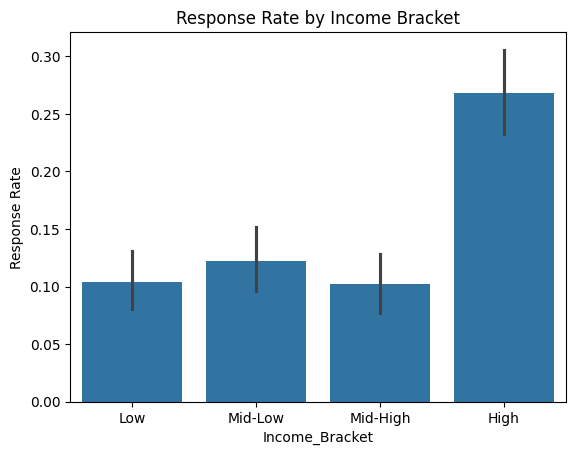

In [32]:
# Response rate by income bracket
df['Income_Bracket'] = pd.qcut(df['Income'], q=4, labels=['Low', 'Mid-Low', 'Mid-High', 'High'])
sns.barplot(data=df, x='Income_Bracket', y='Response')
plt.title('Response Rate by Income Bracket')
plt.ylabel('Response Rate')
plt.show()

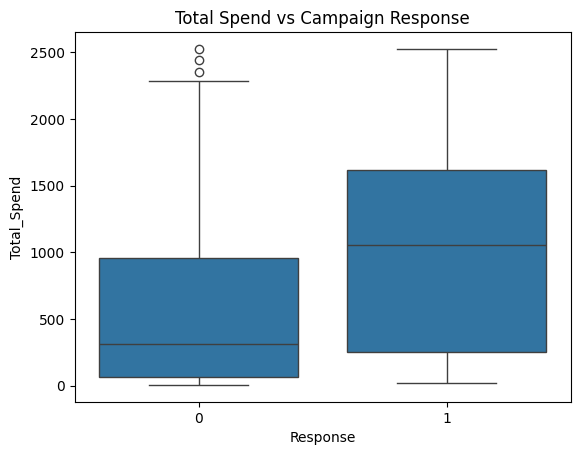

In [33]:
# Does spend history predict response?
sns.boxplot(data=df, x='Response', y='Total_Spend')
plt.title('Total Spend vs Campaign Response')
plt.show()

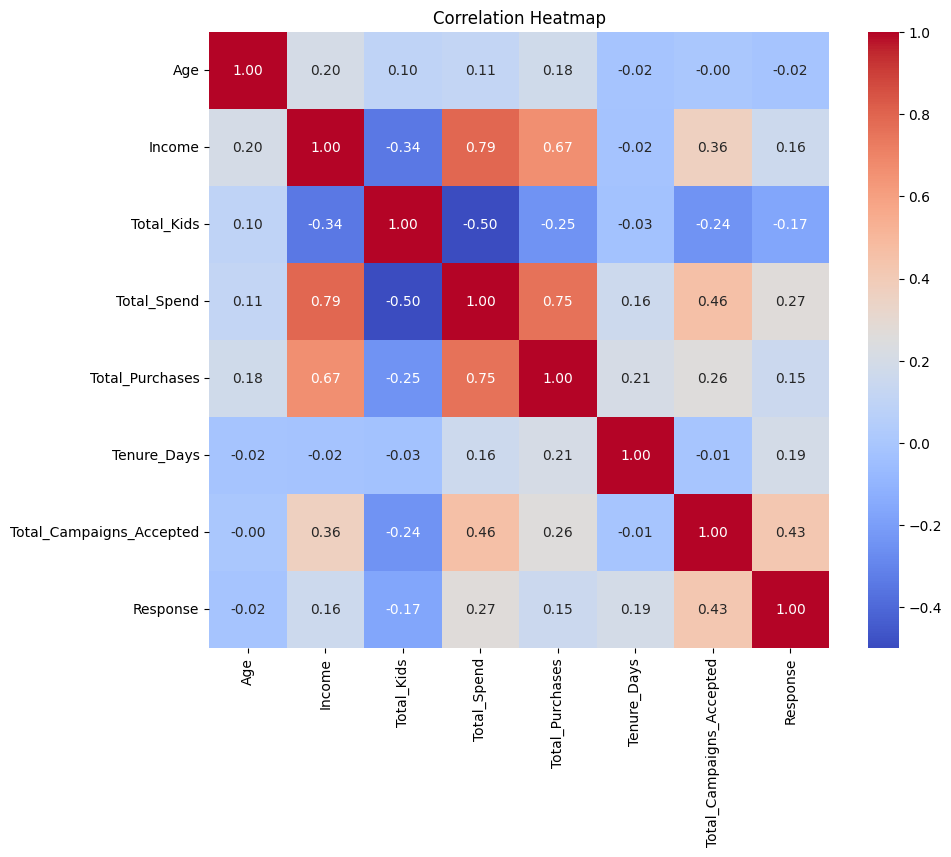

In [34]:
# Correlation heatmap of key numeric variables
corr_cols = ['Age', 'Income', 'Total_Kids', 'Total_Spend', 'Total_Purchases', 'Tenure_Days', 'Total_Campaigns_Accepted', 'Response']
plt.figure(figsize=(10,8))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

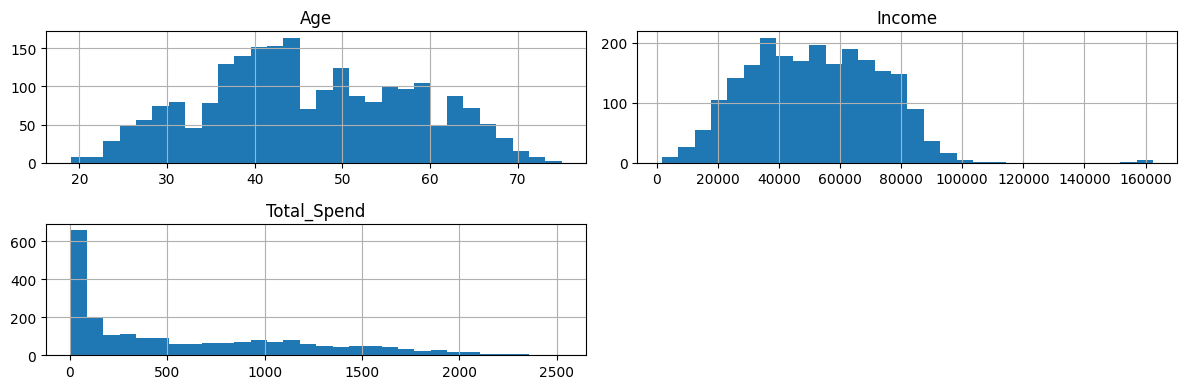

In [35]:
# Distribution of key numeric variables
df[['Age', 'Income', 'Total_Spend']].hist(bins=30, figsize=(12,4))
plt.tight_layout()
plt.show()

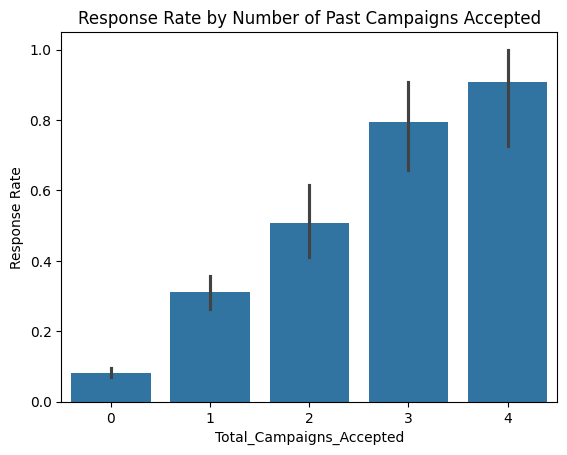

In [36]:
# Does past campaign engagement predict response? (ties directly to your strongest correlation)
sns.barplot(data=df, x='Total_Campaigns_Accepted', y='Response')
plt.title('Response Rate by Number of Past Campaigns Accepted')
plt.ylabel('Response Rate')
plt.show()

In [37]:
# Use the encoded dataframe from Step 8
X = df_encoded.drop(columns=['Response', 'Dt_Customer', 'Income_Bracket'], errors='ignore')
y = df_encoded['Response']

X.shape, y.shape

((2236, 36), (2236,))

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((1788, 36), (448, 36))

In [39]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred)
    }

results_df = pd.DataFrame(results).T
print(results_df)

                     Accuracy  Precision    Recall        F1
Logistic Regression  0.888393   0.697674  0.447761  0.545455
Decision Tree        0.819196   0.400000  0.417910  0.408759
Random Forest        0.879464   0.685714  0.358209  0.470588
SVM                  0.883929   0.777778  0.313433  0.446809


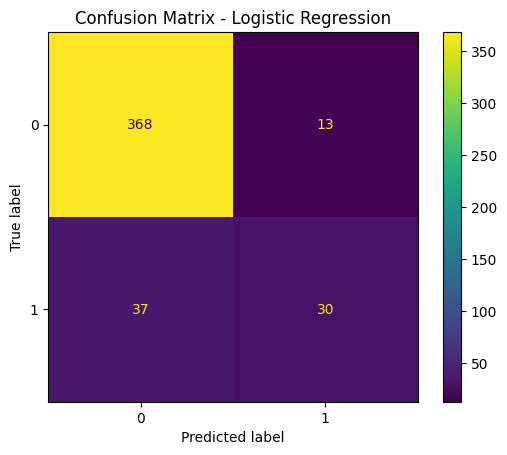

In [41]:
# Confusion matrix for the winning model
from sklearn.metrics import ConfusionMatrixDisplay

best_model = models['Logistic Regression']
y_pred_best = best_model.predict(X_test_scaled)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best)
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [42]:
# Which features matter most?
coefficients = pd.Series(best_model.coef_[0], index=X.columns).sort_values(ascending=False)
print(coefficients.head(10))
print(coefficients.tail(10))

Tenure_Days                 0.971573
Education_PhD               0.479565
Total_Campaigns_Accepted    0.450819
AcceptedCmp3                0.394287
MntMeatProducts             0.334782
AcceptedCmp5                0.315769
AcceptedCmp1                0.271348
NumWebVisitsMonth           0.262081
NumDealsPurchases           0.254610
MntFruits                   0.252927
dtype: float64
Year_Birth                -0.077300
MntSweetProducts          -0.131623
MntWines                  -0.175669
Education_Basic           -0.184595
Total_Kids                -0.192369
Teenhome                  -0.458827
Marital_Status_Together   -0.549076
Marital_Status_Married    -0.588553
NumStorePurchases         -0.645375
Recency                   -0.879898
dtype: float64


In [43]:
models_weighted = {
    'Logistic Regression': LogisticRegression(random_state=42, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, class_weight='balanced'),
    'SVM': SVC(random_state=42, class_weight='balanced')
}

results_weighted = {}
for name, model in models_weighted.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    results_weighted[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred)
    }

results_weighted_df = pd.DataFrame(results_weighted).T
print(results_weighted_df)

                     Accuracy  Precision    Recall        F1
Logistic Regression  0.819196   0.440678  0.776119  0.562162
Decision Tree        0.854911   0.515152  0.507463  0.511278
Random Forest        0.881696   0.718750  0.343284  0.464646
SVM                  0.839286   0.475248  0.716418  0.571429


In [44]:
from sklearn.metrics import f1_score

best_model = LogisticRegression(random_state=42, class_weight='balanced')
best_model.fit(X_train_scaled, y_train)
y_proba = best_model.predict_proba(X_test_scaled)[:, 1]

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred_t = (y_proba >= t).astype(int)
    print(f"Threshold {t}: Precision={precision_score(y_test, y_pred_t):.3f}, Recall={recall_score(y_test, y_pred_t):.3f}, F1={f1_score(y_test, y_pred_t):.3f}")

Threshold 0.3: Precision=0.350, Recall=0.925, F1=0.508
Threshold 0.4: Precision=0.385, Recall=0.851, F1=0.530
Threshold 0.5: Precision=0.441, Recall=0.776, F1=0.562
Threshold 0.6: Precision=0.511, Recall=0.672, F1=0.581
Threshold 0.7: Precision=0.544, Recall=0.552, F1=0.548


Final Model Performance:
Precision: 0.511
Recall: 0.672
F1: 0.581


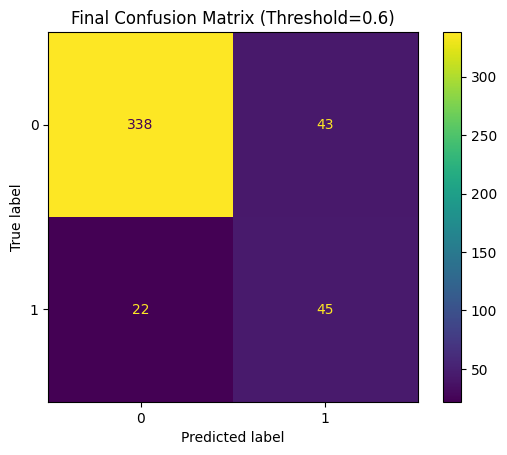

In [45]:
# Final model: Logistic Regression, class-weighted, threshold = 0.6
final_threshold = 0.6
y_pred_final = (y_proba >= final_threshold).astype(int)

print("Final Model Performance:")
print(f"Precision: {precision_score(y_test, y_pred_final):.3f}")
print(f"Recall: {recall_score(y_test, y_pred_final):.3f}")
print(f"F1: {f1_score(y_test, y_pred_final):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final)
plt.title('Final Confusion Matrix (Threshold=0.6)')
plt.show()